In [2]:
import sys
import polars as pl
import pandas as pd
import numpy as np
# Create heatmap with custom colors
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedFormatter, FixedLocator
import matplotlib as mpl
from matplotlib.patches import Patch
import matplotlib.font_manager as fm
from scipy.stats import fisher_exact, mannwhitneyu
from matplotlib.gridspec import GridSpec
from statannotations.Annotator import Annotator

# Force TrueType font embedding (Type 42)
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

font_path = "../../1_allele_collection/4_manuscript_figures/ARIAL.TTF"
fm.fontManager.addfont(font_path)

font_prop = fm.FontProperties(fname=font_path)
# Set font family to one of the accepted fonts
plt.rcParams.update({
    "font.family": font_prop.get_name(),
    "font.sans-serif": ["ARIAL"],
    "font.size": 12,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

# Verify settings
# print(f"pdf.fonttype: {mpl.rcParams['pdf.fonttype']}")
# print(f"ps.fonttype: {mpl.rcParams['ps.fonttype']}")
# print(f"font.family: {mpl.rcParams['font.family']}")

sys.path.append("../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../../2_individual_assay_results")
from analyses_plot_utils import *

In [3]:
al_dual_img_ppi_assayed_dedup = pl.read_csv(
    "../3_outputs/0_all_gene_variants_assayed_summary_key_cols.tsv", separator="\t", infer_schema_length=10000
)

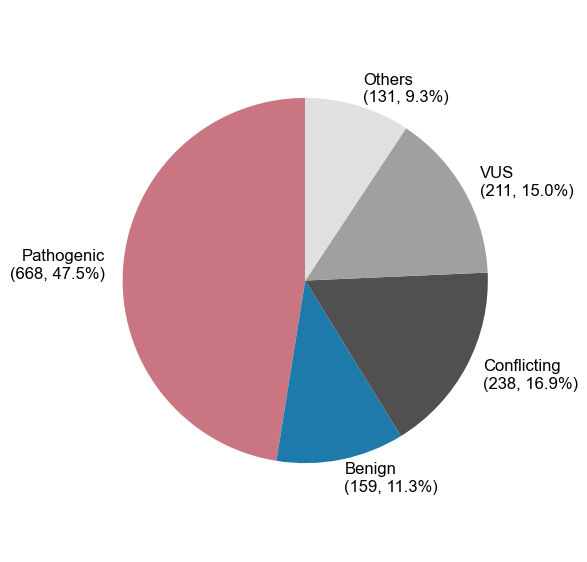

In [5]:
# Create pie chart for ClinVar annotation categories
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
summary_clin_var_counts = al_dual_img_ppi_assayed_dedup.group_by("clinvar_clnsig_clean").agg(pl.len()).to_pandas()
summary_clin_var_counts['clinvar_clnsig_clean'] = pd.Categorical(
    summary_clin_var_counts['clinvar_clnsig_clean'], 
    categories=[c for c in clinvar_order_dict["original"] if "Likely" not in c], 
    ordered=True
)

# Convert to pandas for easier plotting
pie_data = summary_clin_var_counts.sort_values('clinvar_clnsig_clean')
# Calculate percentages
total_count = pie_data["len"].sum()
pie_data["percentage"] = (pie_data["len"] / total_count * 100).round(1)

# Create labels with counts and percentages
labels = [f"{cat}\n({count}, {pct}%)" for cat, count, pct in zip(pie_data["clinvar_clnsig_clean"], 
                                                                 pie_data["len"], 
                                                                 pie_data["percentage"])
]
colors = [palette_dict["clinvar_clnsig_clean"][cat] for cat in pie_data["clinvar_clnsig_clean"]]
# Create pie chart
wedges, texts, autotexts = ax.pie(pie_data["len"], 
                                  labels=labels, 
                                  colors=colors,
                                  autopct="",  # We're including percentages in labels
                                  startangle=90,
                                  counterclock=True,
                                  textprops={'fontsize': 12})
ax.axis('equal')
plt.tight_layout()
plt.show()

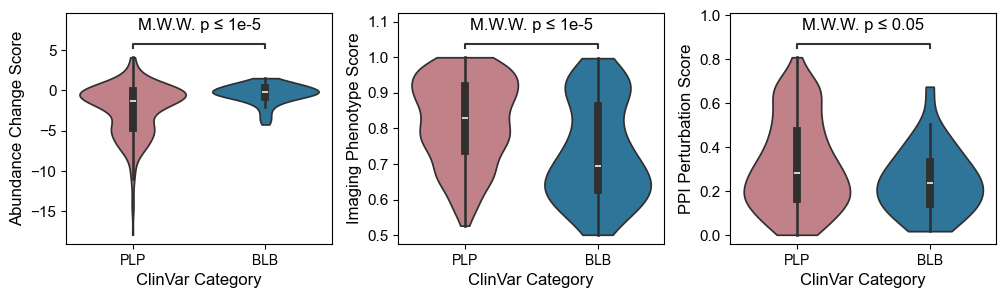

In [21]:
def plot_assay_scores(df, type="box"):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3))
    for i, assay in enumerate(["dualipa_score", "imaging_score", "ppi_score"]):
        if type == "box":
            sns.boxplot(
                data=df.filter(
                    pl.col("clinvar_clnsig_clean").is_in(["Pathogenic", "Benign"])
                ).to_pandas(),
                x="clinvar_clnsig_clean",
                y=assay,
                hue="clinvar_clnsig_clean",
                palette=palette_dict["clinvar_clnsig_clean"],
                width=0.6,
                notch=True,
                order=["Pathogenic", "Benign"],
                ax=axes[i],
                legend=False
            )
        if type == "boxen":
            sns.boxenplot(
                data=df.filter(
                    pl.col("clinvar_clnsig_clean").is_in(["Pathogenic", "Benign"])
                ).to_pandas(),
                x="clinvar_clnsig_clean",
                y=assay,
                hue="clinvar_clnsig_clean",
                palette=palette_dict["clinvar_clnsig_clean"],
                width=0.6,
                order=["Pathogenic", "Benign"],
                ax=axes[i],
                legend=False
            )
        if type == "violin":
            sns.violinplot(
                data=df.filter(
                    pl.col("clinvar_clnsig_clean").is_in(["Pathogenic", "Benign"])
                ).to_pandas(),
                x="clinvar_clnsig_clean",
                y=assay,
                hue="clinvar_clnsig_clean",
                palette=palette_dict["clinvar_clnsig_clean"],
                cut=0,
                order=["Pathogenic", "Benign"],
                ax=axes[i],
                legend=False
            )

        axes[i].set_xlim(-0.5, 1.5)
        # Annotator expects the pairs and corresponding x, hue information
        annotator = Annotator(axes[i], 
                            [("Pathogenic", "Benign")], 
                            data=df.filter(
                                pl.col("clinvar_clnsig_clean").is_in(["Pathogenic", "Benign"]),
                                pl.col(assay).is_not_null()
                            ).to_pandas(), 
                            x="clinvar_clnsig_clean", 
                            y=assay,
                            hue="clinvar_clnsig_clean",
                            order=[c for c in clinvar_order_dict["original"] if "Path" in c or "Benign" in c],
                            verbose=False
        )
        if assay == "dualipa_score":
            test = "Mann-Whitney-ls"
        else:
            test = "Mann-Whitney-gt"

        annotator.configure(test=test, 
                            test_short_name='', 
                            #comparisons_correction="Bonferroni", 
                            text_format='simple', 
                            loc='inside', text_offset=8,
                            # test_kw={'alternative': 'greater'},  # or 'less'
                            verbose=False)
        annotator.apply_test()
        annotator.annotate(line_offset_to_group=0.05, line_offset=0.15)#.apply_and_annotate() | .apply_test()
        # axes[i].grid(alpha=.2, axis="y")
        axes[i].xaxis.set_major_locator(FixedLocator(range(2)))
        axes[i].set_xticklabels(["PLP","BLB"], fontsize=10)
        axes[i].set_xlabel("ClinVar Category")

    axes[0].set_ylabel("Abundance Change Score")
    axes[1].set_ylabel("Imaging Phenotype Score")
    axes[2].set_ylabel("PPI Perturbation Score")
    plt.subplots_adjust(wspace=0.25)
    # fig.savefig(
    #     f"../4_manuscript_figures/assay_phenotyping_score_{type}_dist_clinvar.svg",
    #     format='svg',
    #     dpi=400,
    #     bbox_inches='tight',
    #     transparent=True
    # )
    plt.show()

plot_assay_scores(al_dual_img_ppi_assayed_dedup, "violin")

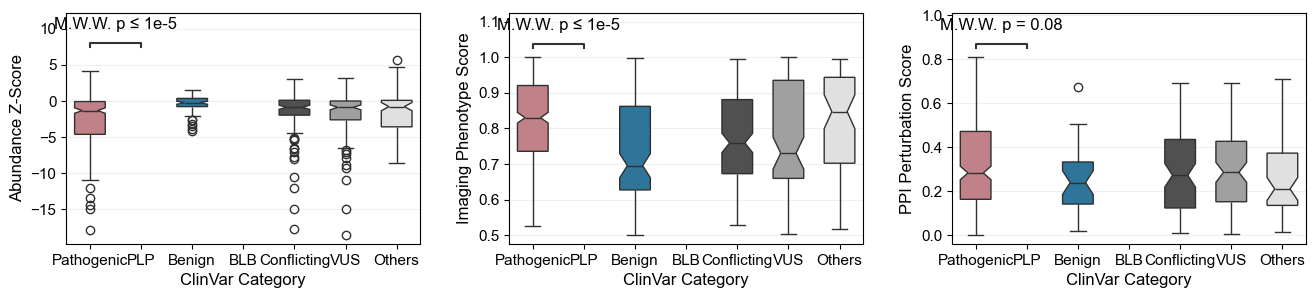

In [22]:
def plot_assay_scores(df, type="box"):
    fig, axes = plt.subplots(1, 3, figsize=(16, 3))
    for i, assay in enumerate(["dualipa_score", "imaging_score", "ppi_score"]):
        if type == "box":
            sns.boxplot(
                data=df.to_pandas(),
                x="clinvar_clnsig_clean",
                y=assay,
                hue="clinvar_clnsig_clean",
                palette=palette_dict["clinvar_clnsig_clean"],
                width=0.6,
                notch=True,
                order=[c for c in clinvar_order_dict["original"] if "Likely" not in c],
                ax=axes[i],
                legend=False
            )
        if type == "boxen":
            sns.boxenplot(
                data=df.to_pandas(),
                x="clinvar_clnsig_clean",
                y=assay,
                hue="clinvar_clnsig_clean",
                palette=palette_dict["clinvar_clnsig_clean"],
                width=0.6,
                order=[c for c in clinvar_order_dict["bio_descending"] if "Likely" not in c],
                ax=axes[i],
                legend=False
            )
        if type == "violin":
            sns.violinplot(
                data=df.to_pandas(),
                x="clinvar_clnsig_clean",
                y=assay,
                hue="clinvar_clnsig_clean",
                palette=palette_dict["clinvar_clnsig_clean"],
                cut=0,
                order=[c for c in clinvar_order_dict["bio_descending"] if "Likely" not in c],
                ax=axes[i],
                legend=False
            )

        # axes[i].set_xlim(-0.5, 1.5)
        # # Annotator expects the pairs and corresponding x, hue information
        annotator = Annotator(axes[i], 
                              [("Pathogenic", "Benign")], 
                              data=df.filter(
                                        # pl.col("clinvar_clnsig_clean").is_in(["Pathogenic", "Benign"]),
                                        pl.col(assay).is_not_null()
                                    ).to_pandas(), 
                            x="clinvar_clnsig_clean", 
                            y=assay,
                            hue="clinvar_clnsig_clean",
                            order=[c for c in clinvar_order_dict["bio_descending"] if "Path" in c or "Benign" in c],
                            verbose=False
        )
        annotator.configure(test="Mann-Whitney",#test='Mann-Whitney-gt', 
                            test_short_name='M.W.W.\n', 
                            #comparisons_correction="Bonferroni", 
                            text_format='simple', 
                            loc='inside', text_offset=8,
                            # test_kw={'alternative': 'greater'},  # or 'less'
                            verbose=False)
        annotator.apply_test()
        annotator.annotate(line_offset_to_group=0.05, line_offset=0.15)#.apply_and_annotate() | .apply_test()
        axes[i].grid(alpha=.2, axis="y")
        # axes[i].xaxis.set_major_locator(FixedLocator(range(2)))
        # axes[i].set_xticklabels(["PLP","BLB"], fontsize=10)
        axes[i].set_xlabel("ClinVar Category")

    axes[0].set_ylabel("Abundance Z-Score")
    axes[1].set_ylabel("Imaging Phenotype Score")
    axes[2].set_ylabel("PPI Perturbation Score")
    plt.subplots_adjust(wspace=0.25)
    # fig.savefig(
    #     f"../4_manuscript_figures/assay_phenotyping_score_{type}_dist_clinvar.svg",
    #     format='svg',
    #     dpi=400,
    #     bbox_inches='tight',
    #     transparent=True
    # )
    plt.show()

plot_assay_scores(al_dual_img_ppi_assayed_dedup, "box")